# Post-COVID Global Inflation — ML Notebook
K-Means clustering + HistGradientBoosting regression.
Run the cells top to bottom (Kernel → Restart & Run All). Keep this notebook in the project folder next to `data/`, `outputs/`, `models/`.

## Step 1 — Preprocessing
```
STEP 1 - DATA PREPROCESSING
Input : data/global_inflation_post_covid.csv  (raw, 100,000 rows)
        data/country_metadata.csv             (second dataset for blending)
Output: data/inflation_cleaned.csv            (cleaned + blended, used by both models and Power BI)
        outputs/preprocessing_report.txt      (before -> steps -> after, for your report)
```

In [1]:
import pandas as pd
import numpy as np

RAW = "data/global_inflation_post_covid.csv"
META = "data/country_metadata.csv"
OUT = "data/inflation_cleaned.csv"

NUM_COLS = ["inflation_rate", "interest_rate", "oil_price", "gdp_growth",
            "unemployment_rate", "money_supply_m2", "exchange_rate_usd",
            "food_price_index", "supply_chain_index"]

report = []
def log(msg):
    print(msg)
    report.append(str(msg))

### 1. Load

In [2]:
# ---------- 1. Load ----------
df = pd.read_csv(RAW)
log("=== BEFORE PREPROCESSING ===")
log(f"Shape: {df.shape}")
log(f"Columns: {list(df.columns)}")
log("Missing values per column:\n" + df.isna().sum().to_string())
log(f"Duplicate rows: {df.duplicated().sum()}")
log("Summary statistics:\n" + df[NUM_COLS].describe().round(2).to_string())

=== BEFORE PREPROCESSING ===
Shape: (100000, 11)
Columns: ['country', 'date', 'inflation_rate', 'interest_rate', 'oil_price', 'gdp_growth', 'unemployment_rate', 'money_supply_m2', 'exchange_rate_usd', 'food_price_index', 'supply_chain_index']
Missing values per column:
country               0
date                  0
inflation_rate        0
interest_rate         0
oil_price             0
gdp_growth            0
unemployment_rate     0
money_supply_m2       0
exchange_rate_usd     0
food_price_index      0
supply_chain_index    0
Duplicate rows: 0
Summary statistics:
       inflation_rate  interest_rate  oil_price  gdp_growth  unemployment_rate  money_supply_m2  exchange_rate_usd  food_price_index  supply_chain_index
count       100000.00      100000.00  100000.00   100000.00          100000.00        100000.00          100000.00         100000.00           100000.00
mean             4.18           2.56      75.03        2.48               5.51         11947.97              46.91        

### 2. Clean

In [3]:
# ---------- 2. Clean ----------
log("\n=== PREPROCESSING STEPS ===")
before = len(df)
df = df.drop_duplicates()
log(f"1. Removed duplicate rows: {before - len(df)}")

df["country"] = df["country"].astype(str).str.strip().str.upper()
log("2. Standardised country codes (trimmed spaces, upper case)")

df["date"] = pd.to_datetime(df["date"], format="%Y-%m", errors="coerce")
bad_dates = df["date"].isna().sum()
df = df.dropna(subset=["date"])
log(f"3. Converted 'date' (YYYY-MM text) to a real date; dropped {bad_dates} unparseable rows")

for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
missing = int(df[NUM_COLS].isna().sum().sum())
df[NUM_COLS] = df.groupby("country")[NUM_COLS].transform(lambda s: s.fillna(s.median()))
log(f"4. Coerced numeric columns; filled {missing} missing values with the country median")

# Outliers: cap at 1st/99th percentile (winsorising) instead of deleting rows
capped = 0
for c in NUM_COLS:
    lo, hi = df[c].quantile([0.01, 0.99])
    capped += int(((df[c] < lo) | (df[c] > hi)).sum())
    df[c] = df[c].clip(lo, hi)
log(f"5. Capped extreme outliers at the 1st/99th percentile ({capped} values adjusted)")

# Feature engineering
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["quarter"] = "Q" + df["date"].dt.quarter.astype(str)
df["real_interest_rate"] = (df["interest_rate"] - df["inflation_rate"]).round(2)
df["inflation_band"] = pd.cut(df["inflation_rate"], bins=[-np.inf, 2, 4, 6, np.inf],
                              labels=["Low (<2%)", "Moderate (2-4%)", "High (4-6%)", "Very High (>6%)"])
df["covid_phase"] = np.select(
    [df["date"] < "2021-01-01", df["date"] < "2023-01-01"],
    ["2020 Shock", "2021-22 Surge"], default="2023-24 Cooling")
log("6. Added features: year, month, quarter, real_interest_rate, inflation_band, covid_phase")


=== PREPROCESSING STEPS ===


1. Removed duplicate rows: 0
2. Standardised country codes (trimmed spaces, upper case)
3. Converted 'date' (YYYY-MM text) to a real date; dropped 0 unparseable rows


4. Coerced numeric columns; filled 0 missing values with the country median


5. Capped extreme outliers at the 1st/99th percentile (16181 values adjusted)
6. Added features: year, month, quarter, real_interest_rate, inflation_band, covid_phase


### 3. Blend with second dataset

In [4]:
# ---------- 3. Blend with second dataset ----------
meta = pd.read_csv(META)
df = df.merge(meta, on="country", how="left")
log(f"7. Blended with country_metadata.csv (name, region, economy type, lat/long); "
    f"unmatched countries: {df['country_name'].isna().sum()}")

7. Blended with country_metadata.csv (name, region, economy type, lat/long); unmatched countries: 0


### 4. Save

In [5]:
# ---------- 4. Save ----------
df["date"] = df["date"].dt.strftime("%Y-%m-%d")
df.to_csv(OUT, index=False)
log("\n=== AFTER PREPROCESSING ===")
log(f"Shape: {df.shape}")
log(f"Columns: {list(df.columns)}")
log(f"Saved -> {OUT}")

with open("outputs/preprocessing_report.txt", "w") as f:
    f.write("\n".join(report))


=== AFTER PREPROCESSING ===
Shape: (100000, 22)
Columns: ['country', 'date', 'inflation_rate', 'interest_rate', 'oil_price', 'gdp_growth', 'unemployment_rate', 'money_supply_m2', 'exchange_rate_usd', 'food_price_index', 'supply_chain_index', 'year', 'month', 'quarter', 'real_interest_rate', 'inflation_band', 'covid_phase', 'country_name', 'region', 'economy_type', 'latitude', 'longitude']
Saved -> data/inflation_cleaned.csv


## Step 2 — K-Means Clustering
```
STEP 2 - K-MEANS CLUSTERING  (unsupervised: group similar economic situations)

Question answered: "Which countries/months share a similar post-COVID economic profile?"

Unit of clustering: one row per COUNTRY-MONTH (20 countries x 60 months = 1,200 rows),
made by averaging the raw records, so each point is "country X in month Y".

Input : data/inflation_cleaned.csv
Output: outputs/kmeans_country_month.csv   -> each country-month + its cluster + PCA x/y   (Power BI)
        outputs/kmeans_country_summary.csv -> each country's dominant cluster + lat/long  (Power BI map)
        outputs/kmeans_cluster_profiles.csv-> average indicator values per cluster        (Power BI)
        outputs/kmeans_k_selection.csv     -> elbow (inertia) + silhouette for k=2..8      (Power BI / report)
        models/kmeans_model.joblib, models/kmeans_scaler.joblib                           (web app)
        outputs/plots/*.png                                                               (report)
```

In [6]:
import pandas as pd
import numpy as np
import joblib
import matplotlib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

FEATURES = ["inflation_rate", "interest_rate", "oil_price", "gdp_growth",
            "unemployment_rate", "money_supply_m2", "exchange_rate_usd",
            "food_price_index", "supply_chain_index"]
FINAL_K = 4          # change after looking at the elbow / silhouette output
RANDOM_STATE = 42

### 1. Load & aggregate

In [7]:
# ---------- 1. Load & aggregate ----------
df = pd.read_csv("data/inflation_cleaned.csv")
meta_cols = ["country", "country_name", "region", "economy_type", "latitude", "longitude"]
cm = (df.groupby(["country", "date"], as_index=False)[FEATURES].mean()
        .merge(df[meta_cols].drop_duplicates(), on="country"))
print("Country-month rows:", cm.shape)

Country-month rows: (1200, 16)


### 2. Scale (K-Means uses distance, so all features must be on the same scale)

In [8]:
# ---------- 2. Scale (K-Means uses distance, so all features must be on the same scale) ----------
scaler = StandardScaler()
X = scaler.fit_transform(cm[FEATURES])

### 3. Choose k: elbow method + silhouette score

In [9]:
# ---------- 3. Choose k: elbow method + silhouette score ----------
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append({"k": k, "inertia": round(km.inertia_, 2),
                 "silhouette": round(silhouette_score(X, km.labels_), 4)})
ksel = pd.DataFrame(rows)
print(ksel.to_string(index=False))
ksel.to_csv("outputs/kmeans_k_selection.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ksel.k, ksel.inertia, "o-"); ax[0].set(title="Elbow method", xlabel="k", ylabel="Inertia (WCSS)")
ax[1].plot(ksel.k, ksel.silhouette, "o-", color="tab:orange"); ax[1].set(title="Silhouette score", xlabel="k", ylabel="Silhouette")
for a in ax: a.axvline(FINAL_K, ls="--", color="grey")
plt.tight_layout(); plt.savefig("outputs/plots/kmeans_elbow_silhouette.png", dpi=150); plt.close()

 k  inertia  silhouette
 2  8418.62      0.2474
 3  7503.93      0.1518
 4  6972.17      0.1427
 5  6598.24      0.1354
 6  6299.98      0.1303
 7  6077.28      0.1126
 8  5864.07      0.1106


### 4. Final model

In [10]:
# ---------- 4. Final model ----------
kmeans = KMeans(n_clusters=FINAL_K, n_init=10, random_state=RANDOM_STATE).fit(X)
cm["cluster_id"] = kmeans.labels_
print(f"\nFinal k={FINAL_K}, silhouette={silhouette_score(X, kmeans.labels_):.3f}")


Final k=4, silhouette=0.143


### 5. Give clusters readable names (ranked by average inflation)

In [11]:
# ---------- 5. Give clusters readable names (ranked by average inflation) ----------
prof = cm.groupby("cluster_id")[FEATURES].mean()
order = prof["inflation_rate"].sort_values().index.tolist()      # lowest -> highest inflation
level = {2: ["Lower", "Higher"],
         3: ["Low", "Medium", "High"],
         4: ["Lowest", "Below-avg", "Above-avg", "Highest"]}.get(FINAL_K, [f"Rank {i+1}" for i in range(FINAL_K)])
pretty = {"interest_rate": "Interest Rate", "oil_price": "Oil Price", "gdp_growth": "GDP Growth",
          "unemployment_rate": "Unemployment", "money_supply_m2": "Money Supply",
          "exchange_rate_usd": "Exchange Rate", "food_price_index": "Food Prices",
          "supply_chain_index": "Supply-Chain Stress"}
# z-score of each cluster's mean vs. the overall mean -> the most distinctive indicator names the cluster
zprof = (prof - cm[FEATURES].mean()) / cm[FEATURES].std()
name_map = {}
for rank, cid in enumerate(order):
    z = zprof.loc[cid].drop("inflation_rate")
    top = z.abs().idxmax()
    trait = f"{'High' if z[top] > 0 else 'Low'} {pretty[top]}"
    name_map[cid] = f"C{rank + 1}: {level[rank]} Inflation, {trait}"
cm["cluster_name"] = cm["cluster_id"].map(name_map)

### 6. PCA to 2-D so clusters can be drawn on a scatter plot

In [12]:
# ---------- 6. PCA to 2-D so clusters can be drawn on a scatter plot ----------
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X)
cm["pca_x"], cm["pca_y"] = pcs[:, 0].round(4), pcs[:, 1].round(4)
print("PCA variance explained:", pca.explained_variance_ratio_.round(3))

PCA variance explained: [0.292 0.14 ]


### 7. Save outputs

In [13]:
# ---------- 7. Save outputs ----------
cm[FEATURES] = cm[FEATURES].round(3)
cm.to_csv("outputs/kmeans_country_month.csv", index=False)

profiles = cm.groupby("cluster_name")[FEATURES].mean().round(2)
profiles.insert(0, "num_country_months", cm.groupby("cluster_name").size())
profiles.reset_index().to_csv("outputs/kmeans_cluster_profiles.csv", index=False)
print("\nCluster profiles:\n", profiles.to_string())

summary = (cm.groupby(meta_cols)
             .agg(dominant_cluster=("cluster_name", lambda s: s.mode()[0]),
                  share_in_dominant=("cluster_name", lambda s: round((s == s.mode()[0]).mean(), 3)),
                  avg_inflation=("inflation_rate", "mean"),
                  avg_interest=("interest_rate", "mean"))
             .round(3).reset_index())
summary.to_csv("outputs/kmeans_country_summary.csv", index=False)
print("\nCountry -> dominant cluster:\n", summary[["country", "dominant_cluster", "share_in_dominant"]].to_string(index=False))

joblib.dump(kmeans, "models/kmeans_model.joblib")
joblib.dump(scaler, "models/kmeans_scaler.joblib")
joblib.dump(name_map, "models/kmeans_cluster_names.joblib")


Cluster profiles:
                                                    num_country_months  inflation_rate  interest_rate  oil_price  gdp_growth  unemployment_rate  money_supply_m2  exchange_rate_usd  food_price_index  supply_chain_index
cluster_name                                                                                                                                                                                                            
C1: Lowest Inflation, High Interest Rate                          283            2.97           3.94      79.09        2.10               5.52         11846.29              52.32            120.81                1.52
C2: Below-avg Inflation, High Supply-Chain Stress                 246            4.15           2.59      40.66        1.66               6.40          9902.21              46.43             99.57                3.47
C3: Above-avg Inflation, High Food Prices                         348            4.35           2.17      79.04 

['models/kmeans_cluster_names.joblib']

### 8. Python visualisations (for the report)

In [14]:
# ---------- 8. Python visualisations (for the report) ----------
fig, ax = plt.subplots(figsize=(8, 6))
for name, g in cm.groupby("cluster_name"):
    ax.scatter(g.pca_x, g.pca_y, s=14, alpha=.7, label=name)
ax.set(title="K-Means clusters (PCA projection)", xlabel="PC1", ylabel="PC2")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("outputs/plots/kmeans_pca_scatter.png", dpi=150); plt.close()

z = (profiles[FEATURES] - profiles[FEATURES].mean()) / profiles[FEATURES].std()
fig, ax = plt.subplots(figsize=(10, 3.5))
im = ax.imshow(z.values, cmap="RdBu_r", aspect="auto", vmin=-2, vmax=2)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(len(z)), z.index, fontsize=8)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, profiles[FEATURES].iloc[i, j], ha="center", va="center", fontsize=7)
plt.colorbar(im, label="z-score vs other clusters"); ax.set_title("Cluster profiles")
plt.tight_layout(); plt.savefig("outputs/plots/kmeans_profile_heatmap.png", dpi=150); plt.close()
print("\nDone. Files written to outputs/ and models/")


Done. Files written to outputs/ and models/


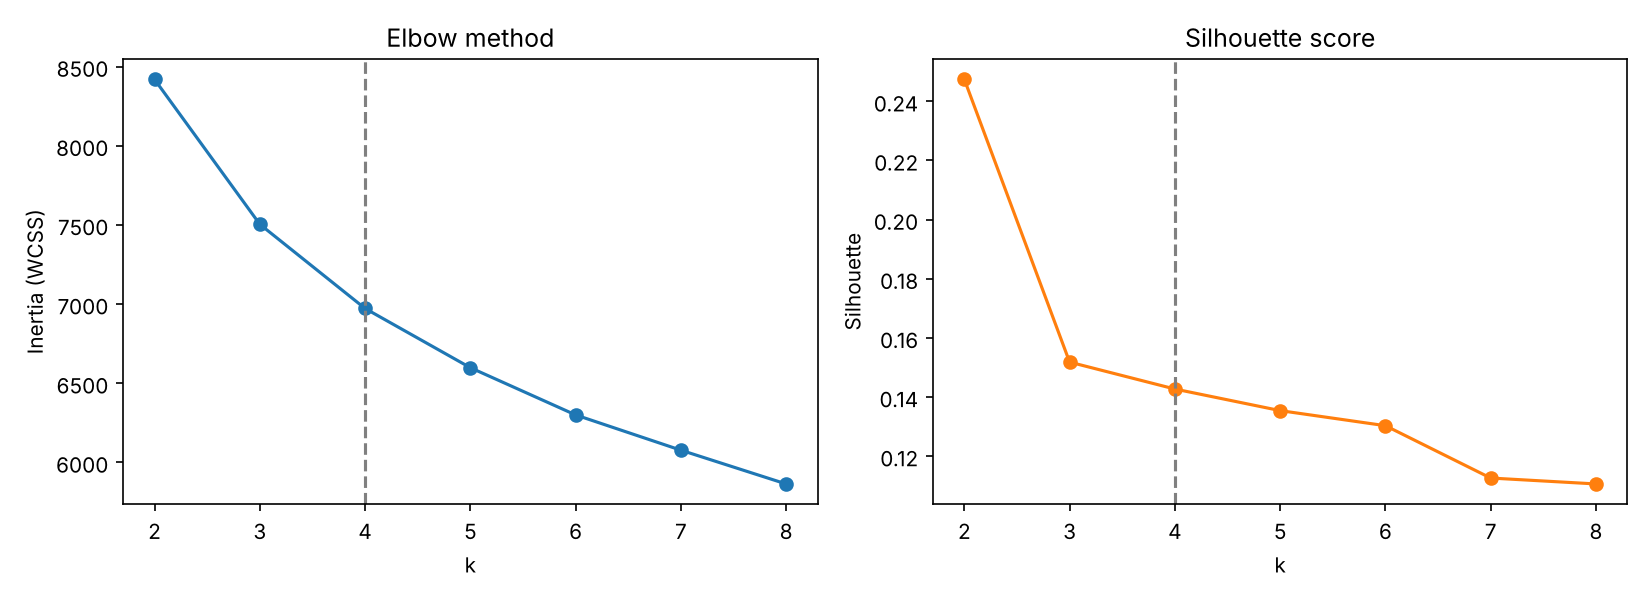

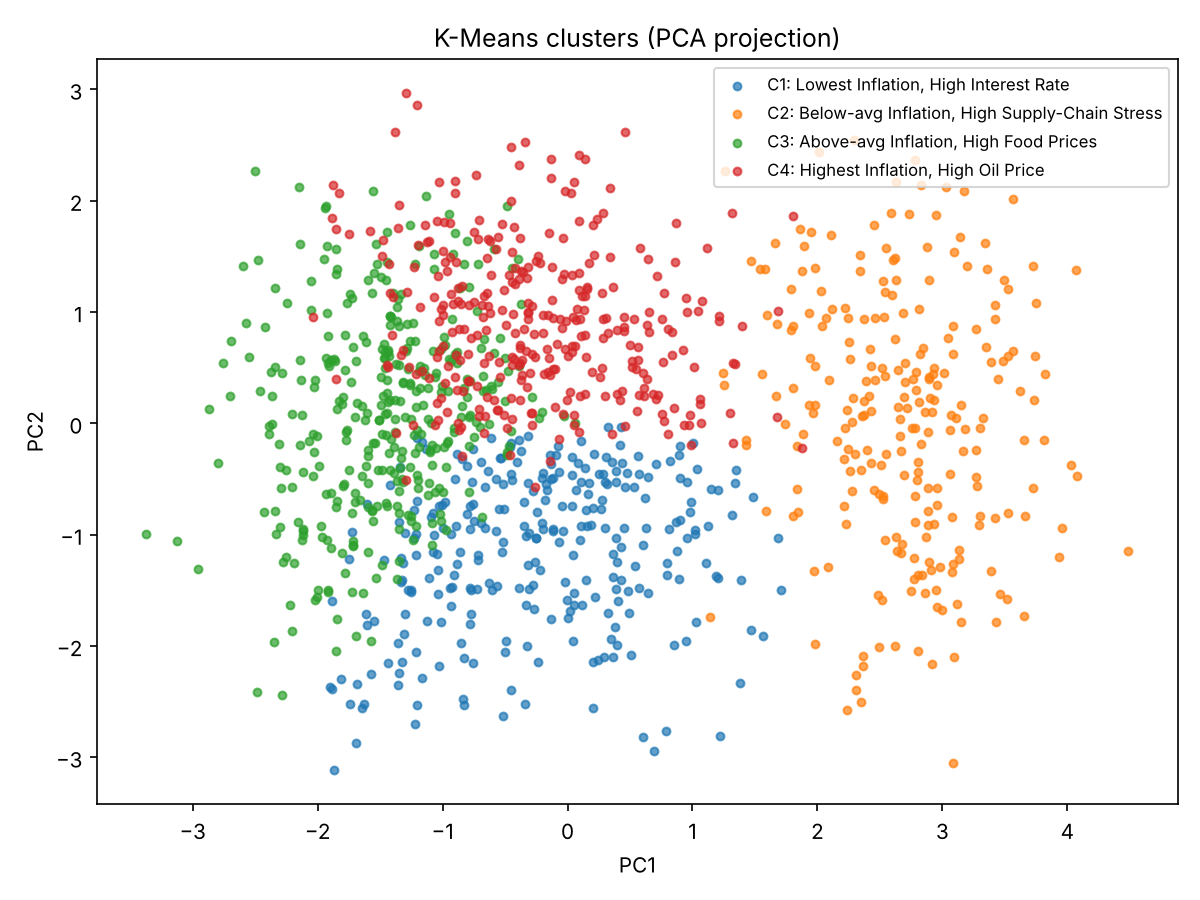

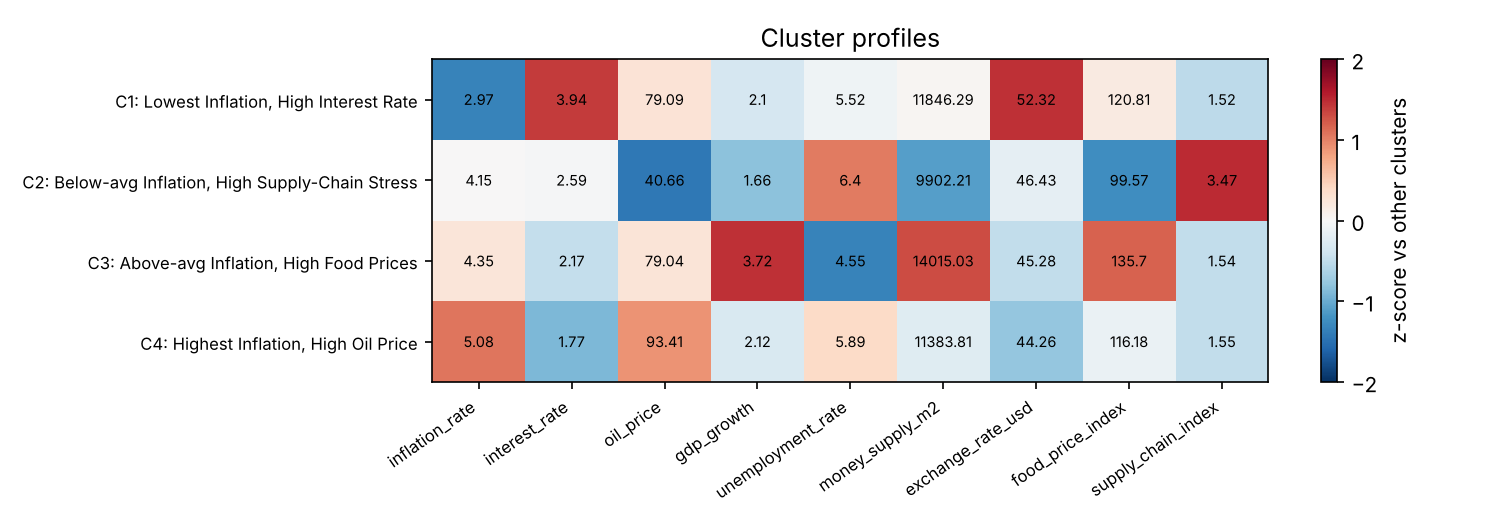

In [15]:
from IPython.display import Image, display
display(Image("outputs/plots/kmeans_elbow_silhouette.png"))
display(Image("outputs/plots/kmeans_pca_scatter.png"))
display(Image("outputs/plots/kmeans_profile_heatmap.png"))

## Step 3 — HistGradientBoosting Regressor
```
STEP 3 - HISTGRADIENTBOOSTING REGRESSOR  (supervised: predict a number)

Question answered: "Given a country's economic indicators for a month, what inflation rate do we expect,
                    and which indicators drive inflation the most?"

Target  : inflation_rate
Features: country (categorical), year, month, interest_rate, oil_price, gdp_growth, unemployment_rate,
          money_supply_m2, exchange_rate_usd, food_price_index, supply_chain_index

Input : data/inflation_cleaned.csv
Output: outputs/hgb_predictions.csv        -> test rows: actual, predicted, error          (Power BI)
        outputs/hgb_metrics.csv            -> MAE, RMSE, R2 (train, test, 5-fold CV)      (Power BI KPI cards)
        outputs/hgb_feature_importance.csv -> permutation importance per feature          (Power BI bar chart)
        outputs/hgb_country_error.csv      -> MAE / RMSE per country                       (Power BI map)
        models/hgb_model.joblib                                                           (web app)
        outputs/plots/*.png                                                               (report)
```

In [16]:
import pandas as pd
import numpy as np
import joblib
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

TARGET = "inflation_rate"
NUM_FEATURES = ["year", "month", "interest_rate", "oil_price", "gdp_growth", "unemployment_rate",
                "money_supply_m2", "exchange_rate_usd", "food_price_index", "supply_chain_index"]
FEATURES = ["country"] + NUM_FEATURES
RANDOM_STATE = 42

### 1. Load

In [17]:
# ---------- 1. Load ----------
df = pd.read_csv("data/inflation_cleaned.csv")
X = df[FEATURES].copy()
X["country"] = X["country"].astype("category")   # HGB handles categories natively, no one-hot needed
y = df[TARGET]

### 2. Train / test split (80 / 20)

In [18]:
# ---------- 2. Train / test split (80 / 20) ----------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (80000, 11)  Test: (20000, 11)


### 3. Model

In [19]:
# ---------- 3. Model ----------
model = HistGradientBoostingRegressor(
    loss="squared_error",
    learning_rate=0.1,
    max_iter=300,             # number of boosting trees
    max_leaf_nodes=31,
    min_samples_leaf=40,
    l2_regularization=1.0,
    categorical_features="from_dtype",
    early_stopping=True,      # stops adding trees when validation score stops improving
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
)
model.fit(X_train, y_train)
print("Trees used (after early stopping):", model.n_iter_)

Trees used (after early stopping): 300


### 4. Evaluate

In [20]:
# ---------- 4. Evaluate ----------
def scores(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
train_s, test_s = scores(y_train, pred_train), scores(y_test, pred_test)
cv = cross_val_score(model, X, y, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="r2")

metrics = pd.DataFrame([
    {"metric": "MAE",  "train": train_s["MAE"],  "test": test_s["MAE"]},
    {"metric": "RMSE", "train": train_s["RMSE"], "test": test_s["RMSE"]},
    {"metric": "R2",   "train": train_s["R2"],   "test": test_s["R2"]},
    {"metric": "CV_R2_mean (5-fold)", "train": np.nan, "test": cv.mean()},
    {"metric": "CV_R2_std (5-fold)",  "train": np.nan, "test": cv.std()},
]).round(4)
# Baseline: always predicting the training mean (shows how much the model adds)
baseline_mae = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
metrics.loc[len(metrics)] = {"metric": "Baseline_MAE (predict mean)", "train": np.nan, "test": round(baseline_mae, 4)}
metrics.to_csv("outputs/hgb_metrics.csv", index=False)
print(metrics.to_string(index=False))

                     metric  train   test
                        MAE 0.3877 0.3874
                       RMSE 0.4885 0.4894
                         R2 0.8850 0.8834
        CV_R2_mean (5-fold)    NaN 0.8818
         CV_R2_std (5-fold)    NaN 0.0017
Baseline_MAE (predict mean)    NaN 1.1640


### 5. Predictions table for Power BI

In [21]:
# ---------- 5. Predictions table for Power BI ----------
out = df.loc[X_test.index, ["country", "country_name", "region", "economy_type", "latitude", "longitude",
                            "date", "year", "quarter", "covid_phase"]].copy()
out["actual_inflation"] = y_test.round(3)
out["predicted_inflation"] = pred_test.round(3)
out["error"] = (out["actual_inflation"] - out["predicted_inflation"]).round(3)   # + = model under-predicted
out["abs_error"] = out["error"].abs()
out["error_band"] = pd.cut(out["abs_error"], [-0.001, 0.25, 0.5, 1, np.inf],
                           labels=["< 0.25", "0.25-0.5", "0.5-1", "> 1"])
out.to_csv("outputs/hgb_predictions.csv", index=False)

country_err = (out.groupby(["country", "country_name", "latitude", "longitude"])
                  .agg(MAE=("abs_error", "mean"),
                       RMSE=("error", lambda e: np.sqrt((e ** 2).mean())),
                       avg_actual=("actual_inflation", "mean"),
                       avg_predicted=("predicted_inflation", "mean"),
                       n_test_rows=("error", "size"))
                  .round(3).reset_index())
country_err.to_csv("outputs/hgb_country_error.csv", index=False)

### 6. Feature importance (permutation: how much R2 drops when a feature is shuffled)

In [22]:
# ---------- 6. Feature importance (permutation: how much R2 drops when a feature is shuffled) ----------
sample = X_test.sample(10000, random_state=RANDOM_STATE)
pi = permutation_importance(model, sample, y_test.loc[sample.index], n_repeats=5,
                            random_state=RANDOM_STATE, scoring="r2")
imp = (pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean, "std": pi.importances_std})
         .sort_values("importance", ascending=False).round(4))
imp.to_csv("outputs/hgb_feature_importance.csv", index=False)
print("\nFeature importance:\n", imp.to_string(index=False))

joblib.dump(model, "models/hgb_model.joblib")
joblib.dump(list(X["country"].cat.categories), "models/hgb_country_categories.joblib")


Feature importance:
            feature  importance    std
           country      0.8576 0.0122
         oil_price      0.2391 0.0029
     interest_rate      0.2012 0.0020
supply_chain_index      0.1570 0.0037
        gdp_growth      0.0604 0.0017
 unemployment_rate      0.0581 0.0011
   money_supply_m2      0.0509 0.0006
             month      0.0372 0.0008
 exchange_rate_usd      0.0364 0.0005
  food_price_index      0.0354 0.0010
              year      0.0023 0.0002


['models/hgb_country_categories.joblib']

### 7. Python visualisations (for the report)

In [23]:
# ---------- 7. Python visualisations (for the report) ----------
s = out.sample(3000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(s.actual_inflation, s.predicted_inflation, s=6, alpha=.4)
lim = [out.actual_inflation.min(), out.actual_inflation.max()]
ax.plot(lim, lim, "r--", label="Perfect prediction")
ax.set(title=f"Actual vs Predicted (test R² = {test_s['R2']:.3f})", xlabel="Actual inflation %", ylabel="Predicted inflation %")
ax.legend(); plt.tight_layout(); plt.savefig("outputs/plots/hgb_actual_vs_predicted.png", dpi=150); plt.close()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(out.error, bins=60, color="tab:purple")
ax.set(title=f"Prediction error distribution (MAE = {test_s['MAE']:.3f})", xlabel="Actual − Predicted", ylabel="Count")
plt.tight_layout(); plt.savefig("outputs/plots/hgb_error_histogram.png", dpi=150); plt.close()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(imp.feature[::-1], imp.importance[::-1], xerr=imp["std"][::-1], color="tab:green")
ax.set(title="Permutation feature importance", xlabel="Drop in R² when shuffled")
plt.tight_layout(); plt.savefig("outputs/plots/hgb_feature_importance.png", dpi=150); plt.close()

trend = out.groupby("date")[["actual_inflation", "predicted_inflation"]].mean()
ax = trend.plot(figsize=(10, 4), title="Average actual vs predicted inflation over time (test set)")
ax.set_ylabel("Inflation %"); plt.tight_layout(); plt.savefig("outputs/plots/hgb_trend.png", dpi=150); plt.close()
print("\nDone. Files written to outputs/ and models/")


Done. Files written to outputs/ and models/


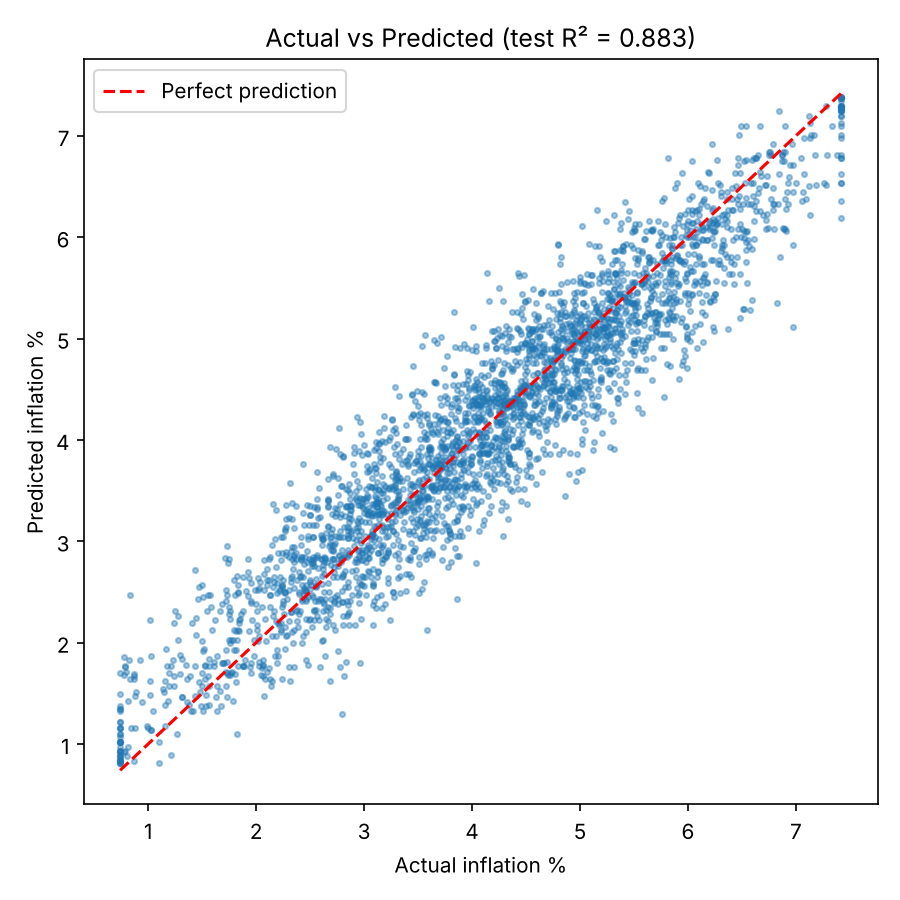

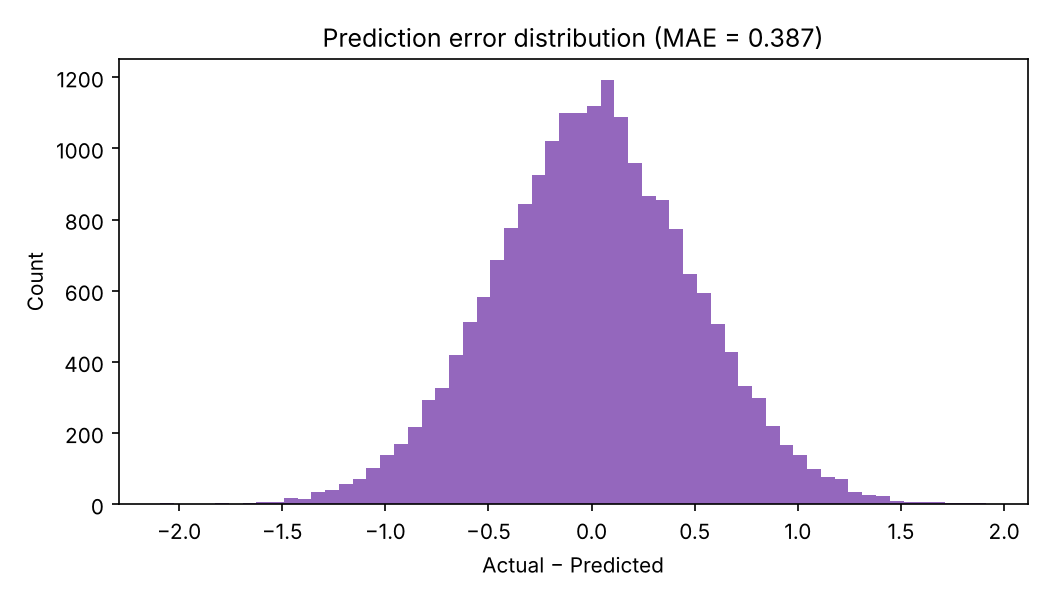

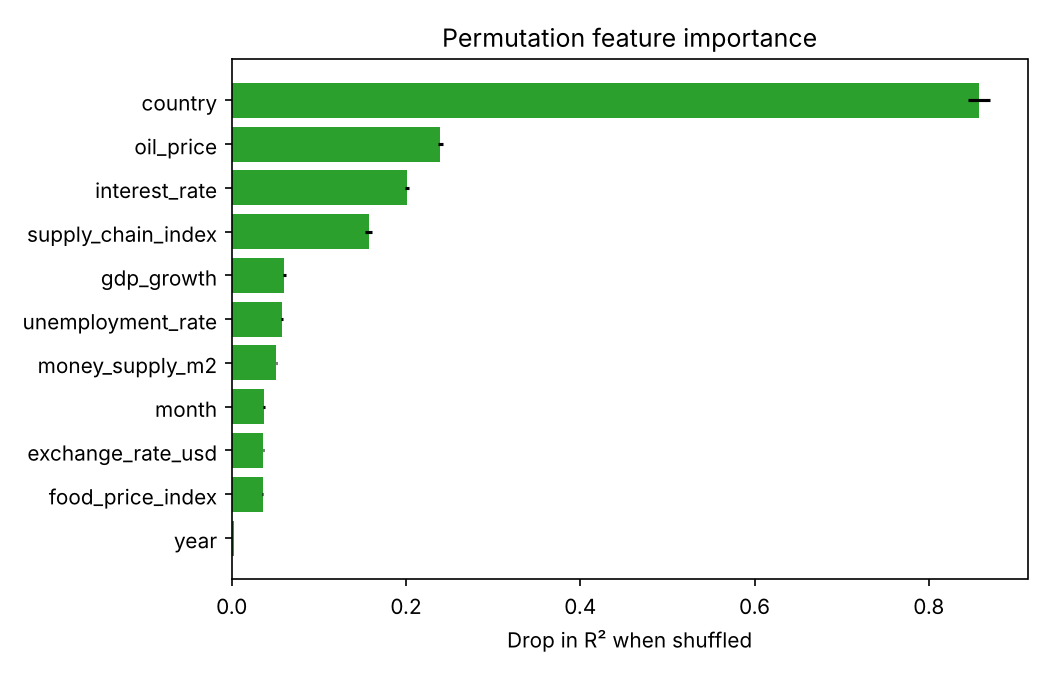

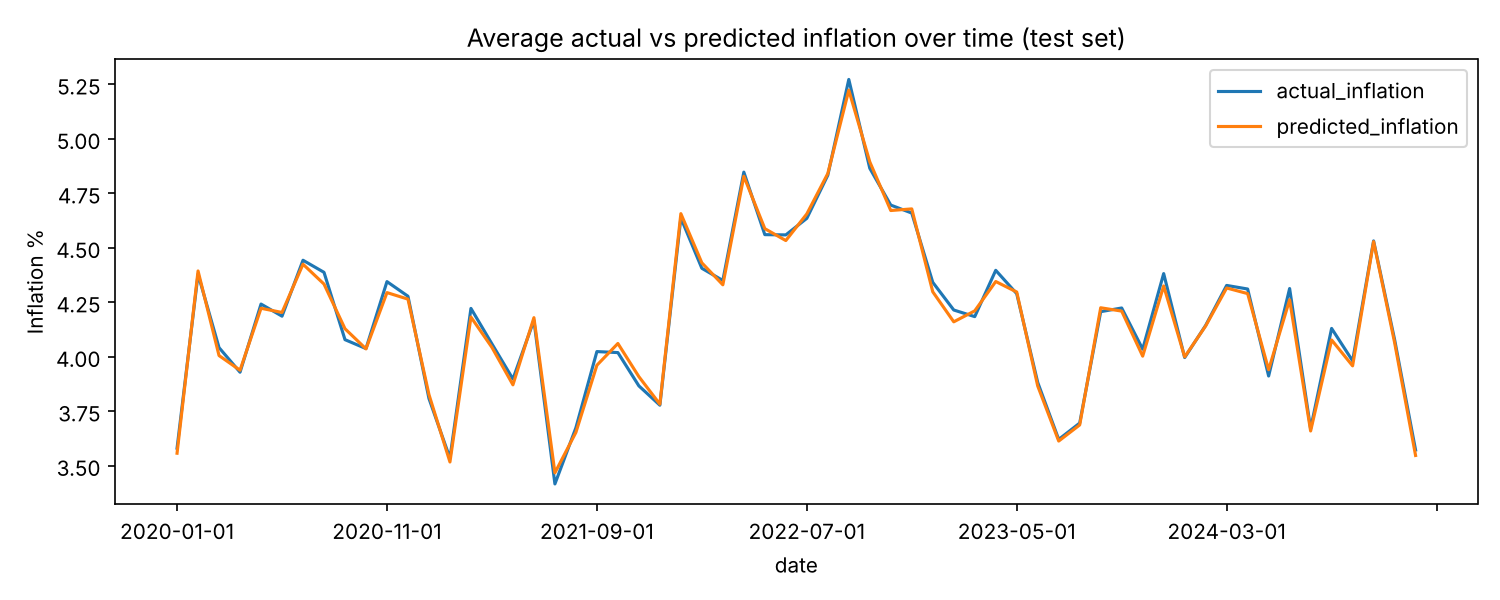

In [24]:
from IPython.display import Image, display
display(Image("outputs/plots/hgb_actual_vs_predicted.png"))
display(Image("outputs/plots/hgb_error_histogram.png"))
display(Image("outputs/plots/hgb_feature_importance.png"))
display(Image("outputs/plots/hgb_trend.png"))